# 第 35 章：结构化产品与自动赎回结构

本章各个算例与各幅图中的每一个数字，按顺序重算一遍。**用 NumPy、SciPy 与 Matplotlib**；
障碍期权公式、触及概率与 Broadie–Glasserman–Kou 平移都是逐条写出来的，而不是从库里调用，
于是正文里的公式与代码完全一致。

| 节 | 复现的内容 | 例／图 |
|---|---|---|
| 1 | 保本票据及其融资利率表 | 35.1 |
| 2 | 四种票据的到期形态，对照存款 | 图 35.1 |
| 3 | 自动赎回结构：公平票息、各项概率、波动率表 | 35.2 |
| 4 | 它的回报分布，以及累积分布图 | 35.3 |
| 5 | 鲨鱼鳍票据，以及返还金的成本 | 35.4 |
| 6 | 双币存款（Garman–Kohlhagen） | 35.5 |
| 7 | 发行人对冲背后的向下敲入看跌期权，以及障碍处的跳跃 | 35.6，图 35.3 |
| 8 | 从票息里读出费用 | 35.7 |

图 35.2 是一张不含数字的决策图，因此这里没有对应的单元。

每个单元都把算出来的值印在本章所印的值旁边。闭式解得到的数字标为 **ok** 或 **DIFFERS**。
例 35.2 与例 35.3 是蒙特卡洛，因此那些单元印出的是*模拟估计*，与本书的数值并列，
在有定义时给出以标准误差计的差距，但从不标记：模拟数字本来就不应逐位吻合。
整本笔记本不到两分钟跑完。

表头保留英文：中文字符在等宽终端里是双宽的，而 Python 的 `%-50s` 按字符数计。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import log, sqrt, exp
from scipy.stats import norm

N = norm.cdf
BAD = []

# 本书的图形配色，取自 preamble.tex：主序列用 exampleframe，对照序列用 snapshotframe，
# 并且同时用线型区分，因为本书以灰度印刷。
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def show(label, got, printed, tol=5e-4):
    """A deterministic figure, printed beside the chapter's. `tol` is absolute."""
    ok = abs(got - printed) <= tol
    if not ok:
        BAD.append(label)
    print("%-50s %12.4f   book %11.4f   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))


def sim(label, got, printed, se=None):
    """A simulated figure: printed beside the chapter's, never flagged, gap in s.e. if known."""
    gap = "" if se is None else "(%+.1f s.e.)" % ((got - printed) / se)
    print("%-50s %12.4f   book %11.4f   %s" % (label, got, printed, gap))


def bs(S, K, T, r, q, sig, call=True):
    """Black-Scholes-Merton with a continuous yield q."""
    d1 = (log(S / K) + (r - q + 0.5 * sig * sig) * T) / (sig * sqrt(T))
    d2 = d1 - sig * sqrt(T)
    if call:
        return S * exp(-q * T) * N(d1) - K * exp(-r * T) * N(d2)
    return K * exp(-r * T) * N(-d2) - S * exp(-q * T) * N(-d1)

## 1. 参与率从哪里来：例 35.1

一张面值 1,000 美元的 5 年期票据。零息债券锁住保本承诺，剩下的钱买平值看涨期权，
因此参与率是倒算出来的余额：

$$p = \frac{F - F e^{-r_f T} - \text{费用}}{c(F, F, T)}$$

只有债券按发行人的融资利率 $r_f$ 定价；看涨期权按 2% 的市场利率在市场上买入，对每个发行人都相同，
因此表中每一行就是相对这一利率的融资利差。指数股息率 2%，波动率 20%。那张表才是这个例子的要点：
在指数不变的情况下，融资利率从 2% 升到 6%，参与率几乎增至三倍。

In [2]:
FACE, T_PPN, Q_PPN, SIG_PPN, R_MKT = 1000.0, 5.0, 0.02, 0.20, 0.02


def ppn(fund, fee=0.0):
    """Example 35.1: bond at the issuer's rate, call bought in the market at R_MKT."""
    bond = FACE * exp(-fund * T_PPN)
    call = bs(FACE, FACE, T_PPN, R_MKT, Q_PPN, SIG_PPN)
    return bond, call, (FACE - bond - fee * FACE) / call


bond, call, part = ppn(0.045)
show("zero-coupon bond to guarantee the 1,000", bond, 798.52, 5e-3)
show("left to buy optionality", FACE - bond, 201.48, 5e-3)
show("at-the-money call, 100% participation", call, 160.10, 5e-3)
show("participation rate, %", 100 * part, 125.8, 0.05)
show("optionality budget after a 2% fee", FACE - bond - 0.02 * FACE, 181.48, 5e-3)
show("participation rate after the fee, %", 100 * ppn(0.045, 0.02)[2], 113.4, 0.05)

print()
print("%-10s %16s %16s" % ("funding", "no fee", "2% fee"))
rows = {}
for fund, want0, want2 in ((0.020, 59.4, 46.9), (0.030, 87.0, 74.5),
                           (0.045, 125.8, 113.4), (0.060, 161.9, 149.4)):
    p0, p2 = 100 * ppn(fund)[2], 100 * ppn(fund, 0.02)[2]
    rows[fund] = p0
    print("%9.1f%% %15.1f%% %15.1f%%    book %.1f%% / %.1f%%" % (100 * fund, p0, p2, want0, want2))
    show("  participation at %.1f%% funding, no fee" % (100 * fund), p0, want0, 0.05)
    show("  participation at %.1f%% funding, 2%% fee" % (100 * fund), p2, want2, 0.05)

print()
print("这笔费用拿走 %.1f 个百分点的参与率；而融资利率从 2%% 升到 6%%，"
      % (100 * (part - ppn(0.045, 0.02)[2])))
print("在指数不变的情况下，参与率乘以 %.2f。" % (rows[0.060] / rows[0.020]))

zero-coupon bond to guarantee the 1,000                798.5162   book    798.5200   ok
left to buy optionality                                201.4838   book    201.4800   ok
at-the-money call, 100% participation                  160.0990   book    160.1000   ok
participation rate, %                                  125.8495   book    125.8000   ok
optionality budget after a 2% fee                      181.4838   book    181.4800   ok
participation rate after the fee, %                    113.3572   book    113.4000   ok

funding              no fee           2% fee
      2.0%            59.4%            46.9%    book 59.4% / 46.9%
  participation at 2.0% funding, no fee                 59.4398   book     59.4000   ok
  participation at 2.0% funding, 2% fee                 46.9476   book     46.9000   ok
      3.0%            87.0%            74.5%    book 87.0% / 74.5%
  participation at 3.0% funding, no fee                 87.0037   book     87.0000   ok
  participation at 3.0% fund

## 2. 四种票据的到期形态：图 35.1

每 100 面值的赎回额，对照同样的 100 按 4% 存一年的所得，这是买方实际可选的简单替代方案。
实线位于虚线之上的那一段，就是买方胜过存款的标的区间，本章从图上读出了四个：
保本票据在 104.4 以上，封顶参与票据在 104 以上，反向可转换票据在障碍 70 及以上的任何水平，
而鲨鱼鳍只在 103.6 与敲出水平 130 之间。下面的单元在细网格上找出同样的区间。

图中的鲨鱼鳍只在到期日观察障碍，这是该图能够精确画出的形式；第 5 节为连续监测的那一种定价。

note                   beats the deposit for S_T in
Principal-protected          104.44 to   150.00
Capped participation         104.00 to   150.00
Reverse convertible           70.00 to   150.00
Shark fin                    103.64 to   130.00
principal-protected: ahead above                       104.4450   book    104.4000   ok
capped participation: ahead above                      104.0010   book    104.0000   ok
reverse convertible: ahead at or above the barrier      70.0000   book     70.0000   ok
shark fin: ahead above                                 103.6370   book    103.6000   ok
shark fin: ... and below the knock-out                 129.9990   book    130.0000   ok


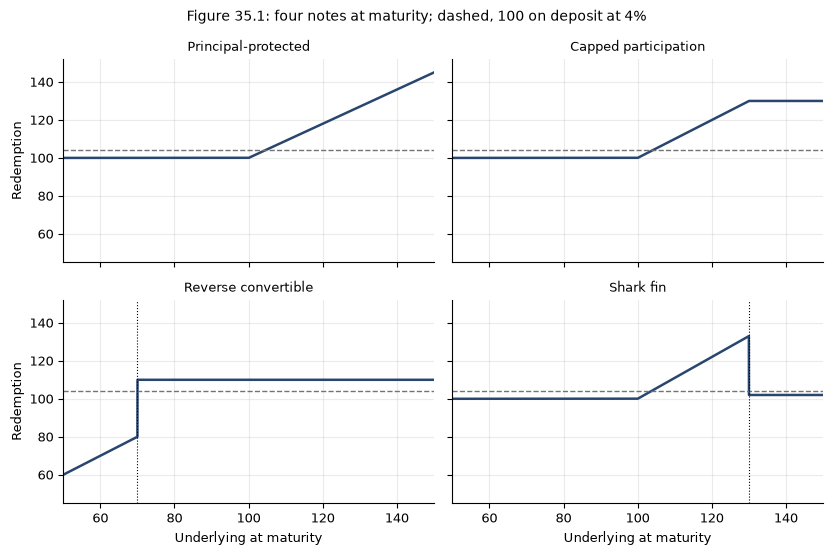

In [3]:
# 图 35.1：每 100 面值的赎回额，初始水平 100，对照 100 按 4% 存一年。
DEPOSIT = 100.0 * 1.04
x = np.linspace(50.0, 150.0, 100_001)
notes = {
    "Principal-protected": 100.0 + 0.9 * np.maximum(x - 100.0, 0.0),                  # (35.1), p = 0.9
    "Capped participation": 100.0 + np.maximum(x - 100.0, 0.0) - np.maximum(x - 130.0, 0.0),
    "Reverse convertible": np.where(x >= 70.0, 110.0, 10.0 + x),                      # c = 10%, H = 70
    "Shark fin": np.where(x < 130.0, 100.0 + 1.10 * np.maximum(x - 100.0, 0.0), 102.0),
}

print("%-22s %26s" % ("note", "beats the deposit for S_T in"))
ahead = {}
for name, v in notes.items():
    win = x[v > DEPOSIT]
    ahead[name] = (win.min(), win.max())
    print("%-22s %12.2f to %8.2f" % (name, win.min(), win.max()))
show("principal-protected: ahead above", ahead["Principal-protected"][0], 104.4, 0.05)
show("capped participation: ahead above", ahead["Capped participation"][0], 104.0, 0.01)
show("reverse convertible: ahead at or above the barrier", ahead["Reverse convertible"][0], 70.0, 0.01)
show("shark fin: ahead above", ahead["Shark fin"][0], 103.6, 0.05)
show("shark fin: ... and below the knock-out", ahead["Shark fin"][1], 130.0, 0.01)

fig, axes = plt.subplots(2, 2, figsize=(8.4, 5.6), sharex=True, sharey=True)
for ax, (name, v) in zip(axes.ravel(), notes.items()):
    ax.plot(x, v, color=BLUE, lw=1.8)
    ax.axhline(DEPOSIT, color="0.45", lw=1.0, ls="--")
    ax.set_title(name, fontsize=9)
    ax.set_xlim(50, 150); ax.set_ylim(45, 152)
for ax in axes[1]:
    ax.set_xlabel("Underlying at maturity")
for ax in axes[:, 0]:
    ax.set_ylabel("Redemption")
axes[1, 0].axvline(70.0, color="black", lw=0.8, ls=":")
axes[1, 1].axvline(130.0, color="black", lw=0.8, ls=":")
fig.suptitle("Figure 35.1: four notes at maturity; dashed, 100 on deposit at 4%", fontsize=10)
plt.tight_layout(); plt.show()

## 3. 为自动赎回结构定价：例 35.2

一张 2 年期票据，挂钩水平为 100 的指数。敲出在 100%，有 2 个月的锁定期、此后按月观察，
因此第一个敲出日是第 3 个月末；敲入在 75%，按日观察。在第 $m$ 个月末被赎回的票据偿还
$1 + c\,m/12$；从未被赎回且从未敲入的偿还 $1 + 2c$；曾敲入且从未被赎回的偿还
$\min(S_T/100, 1)$，没有票息。波动率 25%，利率 2.5%，40 万条 504 个交易日的对偶路径。

**公平票息不需要求根。** 票据的价值对票息是线性的：

$$V(c) = A + c\,B,$$

其中 $A$ 是贴现后的本金部分，$B$ 是每单位年票息对应的贴现计息时间。因此一次模拟就直接给出
$c^{*} = (1 - A)/B$。$B$ 也正是例 35.7 所需要的票息到价值的因子，因此第 8 节沿用这批路径。

这些都是单个种子的*模拟估计*。本章的数字把 200 个种子、每个 40 万条路径合并起来，共 8,000 万条，
公平票息的标准误差因此为 0.005 个百分点。单用种子 35 得到 18.63%，比合并后的 18.42% 高出将近其自身标准误差的三倍，
因此一个种子不足以印出两位小数；下一个单元做合并。

In [4]:
T_AC, R_AC, KI_AC, CALL_AC = 2.0, 0.025, 75.0, 100.0
DAYS, MONTH, FIRST_CALL = 252, 21, 3          # 按日敲入；自第 3 个月起按月敲出
C_BOOK = 0.1842                               # 本章的公平票息，此后各节都用它


def simulate_note(sig, n_paths, seed, chunk=20_000):
    """Antithetic daily paths of the index; returns, per path, the autocall month (0 if never),
    whether the 75% knock-in was breached at any point in the two years, whether it was
    breached while the note was still alive (up to its call date), and S_T.
    Arrays have shape (2, n_paths/2): row 0 the draws, row 1 their mirror images."""
    rng = np.random.default_rng(seed)
    dt, n_steps = 1.0 / DAYS, int(DAYS * T_AC)
    obs = MONTH * np.arange(FIRST_CALL, 25) - 1          # 第 3, ..., 24 个月的最后一天
    out = {"m": [[], []], "ki": [[], []], "kia": [[], []], "sT": [[], []]}
    done = 0
    while done < n_paths // 2:
        h = min(chunk, n_paths // 2 - done)
        z = rng.standard_normal((h, n_steps))
        for side, zz in enumerate((z, -z)):
            S = 100.0 * np.exp(np.cumsum((R_AC - 0.5 * sig * sig) * dt + sig * sqrt(dt) * zz, axis=1))
            above = S[:, obs] >= CALL_AC
            out["m"][side].append(np.where(above.any(axis=1), FIRST_CALL + above.argmax(axis=1), 0))
            out["ki"][side].append(S.min(axis=1) < KI_AC)
            end = np.where(above.any(axis=1), obs[above.argmax(axis=1)], n_steps - 1)   # 票据的最后一天：赎回日或到期日
            out["kia"][side].append(np.minimum.accumulate(S, axis=1)[np.arange(h), end] < KI_AC)
            out["sT"][side].append(S[:, -1])
        done += h
    return {k: np.array([np.concatenate(v[0]), np.concatenate(v[1])]) for k, v in out.items()}


def note_legs(p):
    """Per path, discounted: the principal leg A and the coupon leg B, so the note is A + c B.
    Also the redemption time, which is the note's life."""
    called = p["m"] > 0
    life = np.where(called, p["m"] / 12.0, T_AC)
    disc = np.exp(-R_AC * life)
    principal = np.where(called | ~p["ki"], 1.0, np.minimum(p["sT"] / 100.0, 1.0))
    accrual = np.where(called, p["m"] / 12.0, np.where(p["ki"], 0.0, T_AC))
    return disc * principal, disc * accrual, life


base = simulate_note(0.25, 400_000, seed=35)
A, B, life_ac = note_legs(base)
c_fair = (1.0 - A.mean()) / B.mean()
pair = 0.5 * ((A + c_fair * B)[0] + (A + c_fair * B)[1])      # 对偶的每一对彼此独立
se_c = pair.std() / sqrt(pair.size) / B.mean()

called, ki, kia = base["m"] > 0, base["ki"], base["kia"]
lost = ki & ~called
n = called.size
sim("P(autocalls at some point)", called.mean(), 0.8311, sqrt(called.mean() * (1 - called.mean()) / n))
sim("P(knocks in before being called)", kia.mean(), 0.2153, sqrt(kia.mean() * (1 - kia.mean()) / n))
sim("P(knocked in and never autocalled)", lost.mean(), 0.1645, sqrt(lost.mean() * (1 - lost.mean()) / n))
sim("fair coupon, % per annum", 100 * c_fair, 18.42, 100 * se_c)
print()
print("票息到价值的因子 B = %.4f：每一个百分点的年票息值面值的 %.3f 个百分点"
      % (B.mean(), B.mean()))
print("因此一次模拟就直接给出公平票息 c = (1 - A)/B，无需求根。")

P(autocalls at some point)                               0.8296   book      0.8311   (-2.5 s.e.)
P(knocks in before being called)                         0.2161   book      0.2153   (+1.2 s.e.)
P(knocked in and never autocalled)                       0.1660   book      0.1645   (+2.5 s.e.)
fair coupon, % per annum                                18.6324   book     18.4200   (+2.9 s.e.)

票息到价值的因子 B = 0.3645：每一个百分点的年票息值面值的 0.365 个百分点
因此一次模拟就直接给出公平票息 c = (1 - A)/B，无需求根。


### 票息随种子变动多少

同一张票据用种子 1 至 `N_SEEDS`，每个 40 万条路径，合并成一个估计。按默认的十个种子，各种子的票息在 18.4% 上下
各约十分之一个百分点的范围内散开，合并后的票息为 18.43%，标准误差约 0.02 个百分点。本章合并了 200 个种子、
8,000 万条路径，印出 18.42%，标准误差 0.005；把 `N_SEEDS` 设为 200 即可逐位复现。

此后的每一个单元都使用书中印出的 18.42%，以便其数字与本章对齐。

In [5]:
# 本章的数字把种子 1 至 200 合并起来，每个 40 万条路径，共 8,000 万条。十个种子约一分钟；
# N_SEEDS = 200 可把本章的数字逐位复现，约需二十分钟。
N_SEEDS = 10
draws, tot = [], np.zeros(9)
for s in range(1, N_SEEDS + 1):
    p = simulate_note(0.25, 400_000, seed=s)
    a, b, _ = note_legs(p)
    draws.append(100 * (1.0 - a.mean()) / b.mean())
    pa, pb = 0.5 * (a[0] + a[1]), 0.5 * (b[0] + b[1])      # 对偶路径对彼此独立
    hit = p["m"] > 0
    tot += [pa.size, pa.sum(), pb.sum(), (pa * pa).sum(), (pb * pb).sum(), (pa * pb).sum(),
            hit.mean(), (p["ki"] & ~hit).mean(), p["kia"].mean()]
draws = np.array(draws)
n_pairs, ma, mb = tot[0], tot[1] / tot[0], tot[2] / tot[0]
c_pool = (1.0 - ma) / mb
# 在合并票息下一对路径价值 a + c b 的方差，由累计的各项和算出
var = (tot[3] + c_pool ** 2 * tot[4] + 2.0 * c_pool * tot[5]) / n_pairs - (ma + c_pool * mb) ** 2
se_pool = sqrt(var / n_pairs) / mb
p_call, p_lost, p_kia, n_all = tot[6] / N_SEEDS, tot[7] / N_SEEDS, tot[8] / N_SEEDS, 2 * n_pairs
if N_SEEDS <= 10:
    print("%-6s %s" % ("seed", "  ".join("%6d" % s for s in range(1, N_SEEDS + 1))))
    print("%-6s %s" % ("c, %", "  ".join("%6.2f" % d for d in draws)))
    print()
print("%d 个种子：各种子的票息相差 %.2f 个百分点（标准差）；单用种子 35 得到 %.2f%%"
      % (N_SEEDS, draws.std(ddof=1), 100 * c_fair))
sim("pooled fair coupon, % per annum", 100 * c_pool, 18.42, 100 * se_pool)
sim("pooled P(autocalls at some point)", p_call, 0.8311, sqrt(p_call * (1 - p_call) / n_all))
sim("pooled P(knocks in before being called)", p_kia, 0.2153, sqrt(p_kia * (1 - p_kia) / n_all))
sim("pooled P(knocked in and never autocalled)", p_lost, 0.1645, sqrt(p_lost * (1 - p_lost) / n_all))

seed        1       2       3       4       5       6       7       8       9      10
c, %    18.48   18.49   18.48   18.48   18.41   18.45   18.32   18.38   18.39   18.42

10 个种子：各种子的票息相差 0.06 个百分点（标准差）；单用种子 35 得到 18.63%
pooled fair coupon, % per annum                         18.4299   book     18.4200   (+0.4 s.e.)
pooled P(autocalls at some point)                        0.8311   book      0.8311   (-0.0 s.e.)
pooled P(knocks in before being called)                  0.2152   book      0.2153   (-0.4 s.e.)
pooled P(knocked in and never autocalled)                0.1645   book      0.1645   (-0.0 s.e.)


### 买方看不见的波动率敞口

在本章 18.42% 的票息下，按其他波动率重估这张票据。每个波动率用同一批随机数，
因此这一列的变化只来自波动率。本章那一列在每个波动率下都用那 8,000 万条路径；
这个单元用种子 35 的 40 万条，因此与本章的差距在它所印的标准误差之内。**这张票据做空波动率**：它按 25% 定价，
只要指数的波动比这更大，它就低于面值，而投资者从未有意押注波动率。

In [6]:
# 波动率表：在本书 18.42% 的票息下，按其他波动率重估这张票据。
# 每个波动率用同一个种子（公共随机数），因此这一列是光滑的。
print("%-12s %14s %14s" % ("volatility", "note value", "book"))
values = []
for sig, want in ((0.15, 1.0520), (0.20, 1.0204), (0.25, 1.0000), (0.30, 0.9847), (0.40, 0.9574)):
    a, b, _ = note_legs(base if sig == 0.25 else simulate_note(sig, 400_000, seed=35))
    v = a + C_BOOK * b
    pv = 0.5 * (v[0] + v[1])
    values.append(v.mean())
    print("%11.0f%% %14.4f %14.4f    (s.e. %.4f)" % (100 * sig, v.mean(), want, pv.std() / sqrt(pv.size)))
print()
print("票据价值随波动率上升而单调下降：%s" % all(np.diff(values) < 0))

volatility       note value           book


         15%         1.0518         1.0520    (s.e. 0.0002)


         20%         1.0199         1.0204    (s.e. 0.0002)
         25%         0.9992         1.0000    (s.e. 0.0003)


         30%         0.9837         0.9847    (s.e. 0.0003)


         40%         0.9564         0.9574    (s.e. 0.0004)

票据价值随波动率上升而单调下降：True


## 4. 回报分布的形状：例 35.3

票据取 18.42% 的票息，60 万条路径（种子 3535；本章的表用第 3 节那 8,000 万条），对照单纯持有指数 2 年。总回报不贴现：
在第 $m$ 个月被赎回为 $c\,m/12$，从未被赎回且从未敲入为 $2c$，曾敲入为 $\min(S_T/100, 1) - 1$。

这里的全部计算都在定价测度下进行，因此两种工具按构造都赚无风险利率，而票据更低的均值只反映它更短的存续期。
这里比较的是形状。本章中指数那一列用的是闭式解，因为 $S_T$ 是对数正态的；它印在模拟值下面，
两者之差就是抽样误差。

In [7]:
dist = simulate_note(0.25, 600_000, seed=3535)
m, ki, sT = dist["m"].ravel(), dist["ki"].ravel(), dist["sT"].ravel()
called = m > 0
note = np.where(called, C_BOOK * m / 12.0,
                np.where(ki, np.minimum(sT / 100.0, 1.0) - 1.0, C_BOOK * T_AC))
index = sT / 100.0 - 1.0
life = np.where(called, m / 12.0, T_AC)


def moments(x):
    d = x - x.mean()
    s = x.std()
    return x.mean(), s, (d ** 3).mean() / s ** 3, (d ** 4).mean() / s ** 4 - 3.0


nm, ns, nsk, nku = moments(note)
im, istd, isk, _ = moments(index)
print("%-34s %12s %12s" % ("", "the note", "the index"))
print("%-34s %11.2f%% %11.2f%%" % ("mean total return", 100 * nm, 100 * im))
print("%-34s %11.2f%% %11.2f%%" % ("standard deviation", 100 * ns, 100 * istd))
print("%-34s %12.3f %12.3f" % ("skewness", nsk, isk))
print("%-34s %12.3f %12s" % ("excess kurtosis", nku, "---"))
print("%-34s %11.2f%% %11.2f%%" % ("P(positive)", 100 * (note > 0).mean(), 100 * (index > 0).mean()))
print("%-34s %11.2f%% %12s" % ("P(loss > 25%)", 100 * (note < -0.25).mean(), "---"))
print("%-34s %11.2f%% %11.2f%%" % ("5th percentile", 100 * np.percentile(note, 5),
                                   100 * np.percentile(index, 5)))
print()
for label, got, want in (("note: mean total return, %", 100 * nm, 1.60),
                         ("note: standard deviation, %", 100 * ns, 17.25),
                         ("note: skewness", nsk, -1.59),
                         ("note: excess kurtosis", nku, 2.83),
                         ("note: P(positive), %", 100 * (note > 0).mean(), 83.55),
                         ("note: P(loss > 25%), %", 100 * (note < -0.25).mean(), 11.02),
                         ("note: 5th percentile, %", 100 * np.percentile(note, 5), -40.03),
                         ("index: mean total return, %", 100 * im, 5.13),
                         ("index: standard deviation, %", 100 * istd, 38.36),
                         ("index: skewness", isk, 1.14),
                         ("index: P(positive), %", 100 * (index > 0).mean(), 48.59),
                         ("index: 5th percentile, %", 100 * np.percentile(index, 5), -44.79)):
    sim(label, got, want)

# 指数不需要模拟：S_T 是对数正态的，因此它的每个统计量都有闭式解。
sig2 = 0.25 * sqrt(T_AC)
mu2 = (R_AC - 0.5 * 0.25 ** 2) * T_AC
print()
sim("index, closed form: mean, %", 100 * (exp(R_AC * T_AC) - 1.0), 5.13)
sim("index, closed form: standard deviation, %",
    100 * exp(R_AC * T_AC) * sqrt(exp(sig2 ** 2) - 1.0), 38.36)
sim("index, closed form: skewness", (exp(sig2 ** 2) + 2.0) * sqrt(exp(sig2 ** 2) - 1.0), 1.14)
sim("index, closed form: P(positive), %", 100 * N(mu2 / sig2), 48.59)
sim("index, closed form: 5th percentile, %", 100 * (exp(mu2 + sig2 * norm.ppf(0.05)) - 1.0), -44.79)

                                       the note    the index
mean total return                         1.61%        5.11%
standard deviation                       17.23%       38.30%
skewness                                 -1.586        1.149
excess kurtosis                           2.841          ---
P(positive)                              83.56%       48.60%
P(loss > 25%)                            10.98%          ---
5th percentile                          -40.00%      -44.76%

note: mean total return, %                               1.6127   book      1.6000   
note: standard deviation, %                             17.2322   book     17.2500   
note: skewness                                          -1.5863   book     -1.5900   
note: excess kurtosis                                    2.8415   book      2.8300   
note: P(positive), %                                    83.5618   book     83.5500   
note: P(loss > 25%), %                                  10.9847   book     11.020

### 形状：一个点占了一半的概率

将近一半的分布（49.5%）是一个点：票据在第一个机会就被赎回，回报为 $18.42\% \times 3/12 = 4.61\%$。
因此 25% 分位数与中位数是同一个数，从第 17 到第 65 个百分位数全都是 $+4.61\%$。
盈利平均约 8%，亏损平均约 32%，而胜率约为五比一。均值也检验了定价：
利率乘以平均存续期 $2.5\% \times 0.70$，应当接近模拟出的平均回报。

In [8]:
first = C_BOOK * FIRST_CALL / 12.0                       # 第一个敲出日的回报
at_first = np.isclose(note, first)
pos, neg = note > 0, note < 0
worst = np.sort(note)[: note.size // 100]

sim("median return, %", 100 * np.median(note), 4.61)
sim("E[return | positive], %", 100 * note[pos].mean(), 8.22)
sim("E[return | negative], %", 100 * note[neg].mean(), -32.05)
sim("average of the worst 1%, %", 100 * worst.mean(), -60.23)
sim("mass at the first call date, %", 100 * at_first.mean(), 49.5)
sim("P(negative), note, %", 100 * neg.mean(), 16.45)
sim("P(negative), index, %", 100 * (index < 0).mean(), 51.41)
sim("average life, years", life.mean(), 0.70)
print()
show("return on the first call date, 18.42% x 3/12, %", 100 * first, 4.61, 6e-3)
show("most the note can pay, 2 x 18.42%, %", 100 * C_BOOK * T_AC, 36.84, 5e-3)
show("index percentile at that return (closed form)",
     100 * N((log(1.0 + C_BOOK * T_AC) - mu2) / sig2), 82.0, 0.5)
show("25th percentile = median = first-call return",
     float(np.isclose(np.percentile(note, 25), first) and np.isclose(np.median(note), first)), 1.0, 0.5)
lo = 100 * (note < first - 1e-12).mean()
hi = 100 * (note <= first + 1e-12).mean()
print("从第 %.1f 到第 %.1f 个百分位数都等于首次敲出的回报（本书：第 17 到第 65 个）"
      % (lo, hi))
print("利率 x 平均存续期 = %.2f%%，对照模拟均值 %.2f%%（本书：1.75%% 对 1.60%%）"
      % (100 * R_AC * life.mean(), 100 * nm))
print("盈利平均 %.1f%%，亏损平均 %.1f%%：%.1f 比 1 的不对称，而胜率为 %.1f 比 1"
      % (100 * note[pos].mean(), -100 * note[neg].mean(),
         -note[neg].mean() / note[pos].mean(), pos.mean() / neg.mean()))

median return, %                                         4.6050   book      4.6100   
E[return | positive], %                                  8.2253   book      8.2200   
E[return | negative], %                                -32.0019   book    -32.0500   
average of the worst 1%, %                             -60.1926   book    -60.2300   
mass at the first call date, %                          49.5017   book     49.5000   
P(negative), note, %                                    16.4382   book     16.4500   
P(negative), index, %                                   51.3980   book     51.4100   
average life, years                                      0.7019   book      0.7000   

return on the first call date, 18.42% x 3/12, %          4.6050   book      4.6100   ok
most the note can pay, 2 x 18.42%, %                    36.8400   book     36.8400   ok
index percentile at that return (closed form)           82.1858   book     82.0000   ok
25th percentile = median = first-call return   

### 例 35.3 第二张表旁边的累积分布图

票据的曲线在各个按月敲出的回报之间是平的，在每一处向上跳一级；$+4.61\%$ 处 49.5 个百分点的台阶，
就是上面所说的单点。在零以下，它位于指数曲线之下，因为亏损的可能性小得多（16.45% 对 51.41%），
但它在 $+36.84\%$ 处就到达 1（这是票据最多能支付的回报），而指数超过这一回报的概率只有 18%。
这个单元把图中的几个坐标与本章所印的核对一遍。

note CDF at -40.00%                                      0.0500   book      0.0501   
note CDF at +0.00%                                       0.1644   book      0.1645   
note CDF at +4.61%                                       0.6594   book      0.6595   
note CDF at +6.14%                                       0.7421   book      0.7425   
note CDF at +18.42%                                      0.9269   book      0.9272   
index CDF at -30% (closed form)                          0.1652   book      0.1652   ok
index CDF at +0% (closed form)                           0.5141   book      0.5141   ok
index CDF at +30% (closed form)                          0.7815   book      0.7815   ok


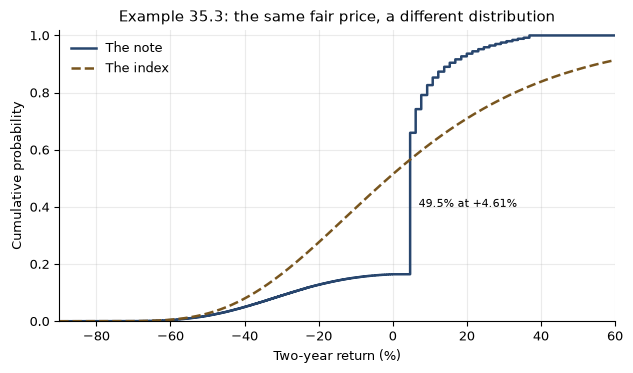

In [9]:
# 例 35.3 第二张表旁边那幅累积分布图。
grid = np.linspace(-90.0, 60.0, 1501)
note_cdf = np.searchsorted(np.sort(100 * note), grid, side="right") / note.size
index_cdf = N((np.log(1.0 + grid / 100.0) - mu2) / sig2)        # 指数用闭式解

for xx, want in ((-40.0, 0.0501), (0.0, 0.1645), (4.61, 0.6595), (6.14, 0.7425), (18.42, 0.9272)):
    sim("note CDF at %+.2f%%" % xx, (100 * note <= xx + 1e-9).mean(), want)
for xx, want in ((-30.0, 0.1652), (0.0, 0.5141), (30.0, 0.7815)):
    show("index CDF at %+.0f%% (closed form)" % xx, N((log(1.0 + xx / 100.0) - mu2) / sig2), want)

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.step(grid, note_cdf, where="post", color=BLUE, lw=1.8, label="The note")
ax.plot(grid, index_cdf, color=AMBER, lw=1.8, ls="--", label="The index")
ax.annotate("%.1f%% at %+.2f%%" % (100 * at_first.mean(), 100 * first), xy=(7, 0.40), fontsize=8)
ax.set_xlim(-90, 60); ax.set_ylim(0, 1.02)
ax.set_xlabel("Two-year return (%)"); ax.set_ylabel("Cumulative probability")
ax.set_title("Example 35.3: the same fair price, a different distribution")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

## 5. 鲨鱼鳍票据及其返还金：例 35.4

一张 1 年期、1,000 美元的票据，利率 3%，标的指数为 100、波动率 25%。普通看涨期权只买得到 26% 的参与率；
130 处的向上敲出看涨期权便宜得多。但这张票据在障碍被触及时还要在到期日支付 2% 的返还金，
而这笔返还金必须从同一笔预算里出。它的成本是贴现后的返还金乘以一年内触及 130 的风险中性概率；
连续监测时，这个概率有闭式解

$$P(\text{触及}) = N\!\left(\frac{-h + \nu T}{\sigma\sqrt{T}}\right)
+ e^{2\nu h/\sigma^2}\, N\!\left(\frac{-h - \nu T}{\sigma\sqrt{T}}\right),
\qquad h = \ln(H/S_0),\; \nu = r - \sigma^2/2.$$

向上敲出看涨期权等于普通看涨期权减去向上敲入看涨期权，用的是第 34.3 节的那些构件。

In [10]:
S_SF, K_SF, H_SF, R_SF, SIG_SF, T_SF = 100.0, 100.0, 130.0, 0.03, 0.25, 1.0


def up_and_out_call(S, K, H, T, r, sig):
    """Section 34.3's blocks for H > K, no dividends: up-and-out = vanilla - up-and-in."""
    lam = (r + 0.5 * sig * sig) / (sig * sig)
    sT = sig * sqrt(T)
    x1 = log(S / H) / sT + lam * sT
    y = log(H * H / (S * K)) / sT + lam * sT
    y1 = log(H / S) / sT + lam * sT
    pw, pw2 = (H / S) ** (2 * lam), (H / S) ** (2 * lam - 2)
    up_in = (S * N(x1) - K * exp(-r * T) * N(x1 - sT)
             - S * pw * (N(-y) - N(-y1)) + K * exp(-r * T) * pw2 * (N(-y + sT) - N(-y1 + sT)))
    return bs(S, K, T, r, 0.0, sig) - up_in


def touch_up(S, H, T, r, sig):
    """Probability that S reaches H > S before T, continuous monitoring (the reflection formula)."""
    nu, h, sT = r - 0.5 * sig * sig, log(H / S), sig * sqrt(T)
    return N((-h + nu * T) / sT) + exp(2 * nu * h / sig ** 2) * N((-h - nu * T) / sT)


bond_sf = 1000.0 * exp(-R_SF * T_SF)
atm = bs(S_SF, K_SF, T_SF, R_SF, 0.0, SIG_SF)
uoc = up_and_out_call(S_SF, K_SF, H_SF, T_SF, R_SF, SIG_SF)
p_touch = touch_up(S_SF, H_SF, T_SF, R_SF, SIG_SF)
rebate = 1000.0 * 0.02 * exp(-R_SF * T_SF) * p_touch
vanilla_part = (1000.0 - bond_sf) / (10.0 * atm)          # 1,000 面值相当于 10 单位水平为 100 的指数
fin_part = (1000.0 - bond_sf - rebate) / (10.0 * uoc)

show("zero-coupon bond", bond_sf, 970.45, 5e-3)
show("budget for the option and its rebate", 1000.0 - bond_sf, 29.55, 5e-3)
show("at-the-money call per 100 of index", atm, 11.3485, 5e-5)
show("vanilla participation, %", 100 * vanilla_part, 26.0, 0.05)
show("up-and-out call at 130, per 100", uoc, 2.1766, 5e-5)
show("touch probability", p_touch, 0.2924, 5e-5)
show("rebate: 1,000 x 2% x e^-0.03 x touch", rebate, 5.68, 5e-3)
show("left for the knock-out call", 1000.0 - bond_sf - rebate, 23.88, 5e-3)
show("shark-fin participation, %", 100 * fin_part, 109.7, 0.05)
show("ratio to the vanilla participation", fin_part / vanilla_part, 4.2, 0.05)
show("what 109.7% participation pays on a 30% move, %", 100 * fin_part * 0.30, 32.9, 0.05)

zero-coupon bond                                       970.4455   book    970.4500   ok
budget for the option and its rebate                    29.5545   book     29.5500   ok
at-the-money call per 100 of index                      11.3485   book     11.3485   ok
vanilla participation, %                                26.0427   book     26.0000   ok
up-and-out call at 130, per 100                          2.1766   book      2.1766   ok
touch probability                                        0.2924   book      0.2924   ok
rebate: 1,000 x 2% x e^-0.03 x touch                     5.6757   book      5.6800   ok
left for the knock-out call                             23.8788   book     23.8800   ok
shark-fin participation, %                             109.7064   book    109.7000   ok
ratio to the vanilla participation                       4.2126   book      4.2000   ok
what 109.7% participation pays on a 30% move, %         32.9119   book     32.9000   ok


## 6. 并非存款的存款：例 35.5

一笔 3 个月、10 万美元的存款，转换汇率 153，而 USD/JPY 即期为 150。存款人卖出了一份执行价 153 的美元看涨期权，
用布莱克–斯科尔斯–默顿公式的 Garman–Kohlhagen 形式估值：以日元利率贴现，美元利率充当收益率 $q$。
所谓收益增强就是这份权利金，再无其他。权利金在起始时收到，收益增强在到期时支付，
因此先按美元利率把权利金累积一个季度，再年化：今天占名义本金的 0.852%，到期时为 0.861%，年化 3.45%。利息无论如何都以美元支付，只有本金可能被转换，
因此在 153 之上，该季度的回报是 $K/X_T - 1$ 加上利息。

In [11]:
X0, K_DCD, R_JPY, R_USD, SIG_FX, T_DCD = 150.0, 153.0, 0.005, 0.045, 0.10, 0.25

# Garman--Kohlhagen：布莱克--斯科尔斯--默顿公式，以日元利率贴现，以美元利率作为 q。
gk = bs(X0, K_DCD, T_DCD, R_JPY, R_USD, SIG_FX)
# 权利金在起始时收到，收益增强在到期时支付，因此先按美元利率把权利金累积一个季度，再年化。
at_maturity = 100 * gk / X0 * exp(R_USD * T_DCD)
premium = at_maturity / T_DCD                             # 年化，占美元名义本金的百分比
show("dollar call struck at 153, yen per dollar", gk, 1.2776, 5e-5)
show("as a % of the notional today", 100 * gk / X0, 0.852, 5e-4)
show("carried to maturity at the dollar rate, %", at_maturity, 0.861, 5e-4)
show("annualized, %", premium, 3.45, 5e-3)
show("deposit plus premium: the advertised rate, %", 100 * R_USD + premium, 7.95, 5e-3)

print()
print("%-14s %-14s %16s" % ("USD/JPY at T", "repaid in", "quarter's return"))
quarter = (100 * R_USD + premium) / 4 / 100               # 利息无论如何都以美元支付
for XT, want in ((140, 1.99), (150, 1.99), (153, 1.99), (160, -2.39), (165, -5.29), (175, -10.59)):
    ret = quarter + (0.0 if XT <= K_DCD else K_DCD / XT - 1.0)
    print("%-14d %-14s %15.2f%%    book %+.2f%%"
          % (XT, "dollars" if XT <= K_DCD else "yen at 153", 100 * ret, want))
    show("  return at %d, %%" % XT, 100 * ret, want, 6e-3)

dollar call struck at 153, yen per dollar                1.2776   book      1.2776   ok
as a % of the notional today                             0.8518   book      0.8520   ok
carried to maturity at the dollar rate, %                0.8614   book      0.8610   ok
annualized, %                                            3.4456   book      3.4500   ok
deposit plus premium: the advertised rate, %             7.9456   book      7.9500   ok

USD/JPY at T   repaid in      quarter's return
140            dollars                   1.99%    book +1.99%
  return at 140, %                                       1.9864   book      1.9900   ok
150            dollars                   1.99%    book +1.99%
  return at 150, %                                       1.9864   book      1.9900   ok
153            dollars                   1.99%    book +1.99%
  return at 153, %                                       1.9864   book      1.9900   ok
160            yen at 153               -2.39%    book -2.39%


## 7. 发行人的对冲：例 35.6

发行人做多票据内嵌的向下敲入看跌期权：执行价 100、障碍 75、1 年期，波动率与利率取例 35.2 的 25% 与 2.5%。
在障碍之上，其价值用第 34.3 节的向下敲入看跌期权公式；在障碍处或障碍之下，它已经敲入，
就是一份普通看跌期权。delta 用在障碍同一侧取的中心差分。

随着指数跌向障碍，delta 的绝对值超过 1，因此发行人的对冲（一个指数多头）从 130 处名义本金的约 5%
增长到 75 上方的约 102%。然后障碍被触及，delta 跳变 $+0.19$：发行人卖出约名义本金的 19%，
而它的买盘随之放缓：障碍之下每个指数点约为名义本金的 1.4%，障碍之上为 1.6%。

In [12]:
K_DI, H_DI, R_DI, SIG_DI, T_DI = 100.0, 75.0, 0.025, 0.25, 1.0


def down_and_in_put(S, K, H, T, r, sig):
    """Section 34.3's down-and-in put for H < K, no dividends. Below the barrier it has
    already knocked in, so it is the vanilla put."""
    if S <= H:
        return bs(S, K, T, r, 0.0, sig, call=False)
    lam = (r + 0.5 * sig * sig) / (sig * sig)
    sT = sig * sqrt(T)
    x1 = log(S / H) / sT + lam * sT
    y = log(H * H / (S * K)) / sT + lam * sT
    y1 = log(H / S) / sT + lam * sT
    pw, pw2 = (H / S) ** (2 * lam), (H / S) ** (2 * lam - 2)
    return (-S * N(-x1) + K * exp(-r * T) * N(-x1 + sT)
            + S * pw * (N(y) - N(y1)) - K * exp(-r * T) * pw2 * (N(y - sT) - N(y1 - sT)))


def dip(S, H=H_DI):
    return down_and_in_put(S, K_DI, H, T_DI, R_DI, SIG_DI)


def dip_delta(S, h=1e-4):
    return (dip(S + h) - dip(S - h)) / (2 * h)


print("%-8s %12s %10s %18s" % ("index", "value", "delta", "book"))
for S, v, d in ((130, 0.706, -0.055), (110, 3.128, -0.220), (100, 6.160, -0.399),
                (90, 11.365, -0.652), (80, 19.262, -0.921), (76, 23.124, -1.006),
                (75.33, 23.802, -1.017), (74.67, 24.411, -0.827), (74, 24.968, -0.836),
                (70, 28.414, -0.885)):
    print("%-8.2f %12.3f %10.3f %11.3f / %+.3f" % (S, dip(S), dip_delta(S), v, d))
    show("  value at %.2f" % S, dip(S), v)
    show("  delta at %.2f" % S, dip_delta(S), d)

print()
jump = dip_delta(74.67) - dip_delta(75.33)
show("delta jump at the barrier", jump, 0.19, 5e-3)
show("hedge at 130, % of notional", -100 * dip_delta(130.0), 5.5, 0.05)
show("hedge just above the barrier, % of notional", -100 * dip_delta(75.33), 101.7, 0.05)

index           value      delta               book
130.00          0.706     -0.055       0.706 / -0.055
  value at 130.00                                        0.7064   book      0.7060   ok
  delta at 130.00                                       -0.0548   book     -0.0550   ok
110.00          3.128     -0.220       3.128 / -0.220
  value at 110.00                                        3.1285   book      3.1280   ok
  delta at 110.00                                       -0.2204   book     -0.2200   ok
100.00          6.160     -0.399       6.160 / -0.399
  value at 100.00                                        6.1604   book      6.1600   ok
  delta at 100.00                                       -0.3992   book     -0.3990   ok
90.00          11.365     -0.652      11.365 / -0.652
  value at 90.00                                        11.3651   book     11.3650   ok
  delta at 90.00                                        -0.6517   book     -0.6520   ok
80.00          19.262     -0

### 按日监测

票据的敲入按日观察，而不是连续观察。第 34.6 节的 Broadie–Glasserman–Kou 修正，
把一年监测 $m$ 次的障碍当作一个远离现价、平移了 $\beta\sigma\sqrt{T/m}$ 的连续障碍来定价，
其中 $\beta = 0.5826$。对向下障碍，这把 75 移到 74.32，并使 100 处的价值从 6.160 降到 5.956。
这个单元把平移后的公式与对按日监测期权的直接模拟作比较；delta 的形状及其在障碍处的跳跃基本不变，
因此例中按连续障碍列表。

In [13]:
# 按日监测：第 34.6 节的修正把障碍推离现价。
BETA = 0.5826
H_daily = H_DI * exp(-BETA * SIG_DI * sqrt(T_DI / 252))
show("daily-monitoring effective barrier", H_daily, 74.32, 5e-3)
show("value at 100, continuous barrier", dip(100.0), 6.160)
show("value at 100, daily barrier", dip(100.0, H_daily), 5.956)

# 一次独立核验：直接模拟按日监测的期权。
rng = np.random.default_rng(356)
z = rng.standard_normal((100_000, 252))
z = np.concatenate([z, -z])
dt = T_DI / 252
paths = 100.0 * np.exp(np.cumsum((R_DI - 0.5 * SIG_DI ** 2) * dt + SIG_DI * sqrt(dt) * z, axis=1))
pay = np.where(paths.min(axis=1) < H_DI, np.maximum(K_DI - paths[:, -1], 0.0), 0.0) * exp(-R_DI * T_DI)
pay = 0.5 * (pay[:100_000] + pay[100_000:])
mc_v, mc_se = pay.mean(), pay.std() / sqrt(pay.size)
print()
print("蒙特卡洛，按日敲入                    %.4f   标准误差 %.4f" % (mc_v, mc_se))
print("平移障碍后的公式                      %.4f   %+.1f 个标准误差" % (dip(100.0, H_daily), (dip(100.0, H_daily) - mc_v) / mc_se))
print("连续障碍的公式                        %.4f   %+.1f 个标准误差" % (dip(100.0), (dip(100.0) - mc_v) / mc_se))

daily-monitoring effective barrier                      74.3150   book     74.3200   ok
value at 100, continuous barrier                         6.1604   book      6.1600   ok
value at 100, daily barrier                              5.9562   book      5.9560   ok



蒙特卡洛，按日敲入                    5.9562   标准误差 0.0229
平移障碍后的公式                      5.9562   -0.0 个标准误差
连续障碍的公式                        6.1604   +8.9 个标准误差


### 图 35.3

左图：障碍上方（实线）与下方（虚线）的 delta；75 处的缺口就是这一不连续点；
缺口两侧的斜率就是稳定性对冲流：在 90 附近最陡，障碍之下比障碍之上平缓，因此买入在 75 处减弱，而不是终止。右图：买方在到期时每 100 面值所得的金额，不含票息：
从未敲入则为面值，曾敲入则为 $\min(S_T, 100)$。这个单元先把图中的五个坐标与本章所印的核对一遍。

Figure 35.3 delta at 75.05                              -1.0218   book     -1.0218   ok
Figure 35.3 delta at 100.34                             -0.3918   book     -0.3919   ok
Figure 35.3 delta at 130.10                             -0.0544   book     -0.0544   ok
Figure 35.3 delta at 74.67                              -0.8273   book     -0.8273   ok
Figure 35.3 delta at 65.80                              -0.9264   book     -0.9264   ok


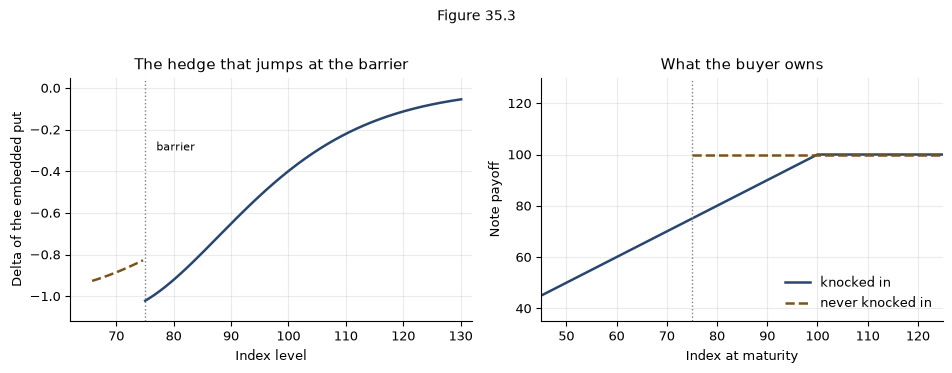

In [14]:
# 图 35.3。左：障碍上方与下方的 delta。右：每 100 面值的票据到期收益，不含票息：
# 从未敲入则为面值，曾敲入则为 min(S_T, 100)。
for S, want in ((75.05, -1.0218), (100.34, -0.3919), (130.10, -0.0544), (74.67, -0.8273), (65.80, -0.9264)):
    show("Figure 35.3 delta at %.2f" % S, dip_delta(S), want)

above = np.linspace(75.05, 130.1, 300)
below = np.linspace(65.8, 74.67, 60)
fig, (axL, axR) = plt.subplots(1, 2, figsize=(9.6, 3.6))
axL.plot(above, [dip_delta(s) for s in above], color=BLUE, lw=1.8)
axL.plot(below, [dip_delta(s) for s in below], color=AMBER, lw=1.8, ls="--")
axL.axvline(H_DI, color="0.5", lw=1.0, ls=":")
axL.annotate("barrier", xy=(77, -0.30), fontsize=8)
axL.set_xlim(62, 132); axL.set_ylim(-1.12, 0.05)
axL.set_xlabel("Index level"); axL.set_ylabel("Delta of the embedded put")
axL.set_title("The hedge that jumps at the barrier")

ST = np.linspace(45.0, 125.0, 161)
axR.plot(ST, np.minimum(ST, 100.0), color=BLUE, lw=1.8, label="knocked in")
ok = ST >= H_DI
axR.plot(ST[ok], np.full_like(ST[ok], 100.0), color=AMBER, lw=1.8, ls="--", label="never knocked in")
axR.axvline(H_DI, color="0.5", lw=1.0, ls=":")
axR.set_xlim(45, 125); axR.set_ylim(35, 130)
axR.set_xlabel("Index at maturity"); axR.set_ylabel("Note payoff")
axR.set_title("What the buyer owns"); axR.legend(frameon=False, loc="lower right")
fig.suptitle("Figure 35.3", y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

## 8. 从票息里读出费用：例 35.7

票据在 18.42% 的票息上按面值定价；设它以 1,000 发行、支付 12.65%。被让掉的价值，
是票息的削减量乘以第 3 节的票息到价值的因子 $B$，本章把它印为 0.366。

$B$ 并不是那 0.70 年的平均存续期。一张敲入且从未被赎回的票据会存续满 2 年而完全不付票息，
这些路径占总数的 16.45%，各存续 2 年，合计占去 0.70 年中的 0.33 年；付息路径贡献其余的 0.37 年，贴现后即为 0.366。单元的最后几行把平均存续期拆开来说明这一点。

那几行计算用的是本章的 0.366，按精确值核对。因子本身，以及在同一批路径上对 12.65% 票据的直接估值，
都是模拟估计；跨种子平均，这个因子约为 0.366，而本笔记本的种子给出 0.365。

In [15]:
C_SOLD = 0.1265                                            # 票据实际发行时的票息
factor = B.mean()                                         # 第 3 节的票息端，每单位票息
sim("coupon-to-value factor", factor, 0.366)
show("value given up, (18.42 - 12.65) x 0.366, % of face", (18.42 - 12.65) * 0.366, 2.11, 5e-3)
show("fair value per 1,000", 1000 * (1 - (18.42 - 12.65) * 0.366 / 100), 979.0, 0.5)
show("annualized over a 0.70-year life, %", (18.42 - 12.65) * 0.366 / 0.70, 3.0, 0.05)

# 直接的做法：在同一批路径上为 12.65% 的票据估值。它与本书吻合的程度，
# 取决于本笔记本的公平票息与 18.42% 吻合的程度。
a, b, lf = A.ravel(), B.ravel(), life_ac.ravel()
sim("simulated value of the 12.65% note, per 1,000", 1000 * (a.mean() + C_SOLD * b.mean()), 979.0)

# 为什么这个因子不是平均存续期：敲入的路径存续满两年，却不计任何票息。
lost_paths = (base["ki"] & (base["m"] == 0)).ravel()
print()
print("平均存续期                                     %.3f 年" % lf.mean())
print("  其中来自敲入且从未敲出的路径                 %.3f 年" % (lf * lost_paths).mean())
print("计息时间，未贴现                               %.3f 年" % np.where(lost_paths, 0.0, lf).mean())
print("同一量贴现后：即因子 B                         %.3f" % factor)

coupon-to-value factor                                   0.3645   book      0.3660   
value given up, (18.42 - 12.65) x 0.366, % of face       2.1118   book      2.1100   ok
fair value per 1,000                                   978.8818   book    979.0000   ok
annualized over a 0.70-year life, %                      3.0169   book      3.0000   ok
simulated value of the 12.65% note, per 1,000          978.1917   book    979.0000   

平均存续期                                     0.703 年
  其中来自敲入且从未敲出的路径                 0.332 年
计息时间，未贴现                               0.371 年
同一量贴现后：即因子 B                         0.365


## 复现了什么

如果下面的单元没有报告任何差异，本笔记本中每一个闭式解得到的数字都与本章吻合，
而模拟得到的数字已在上面与本书的数值并列印出。

这里有一个值得养成的习惯。**当价格对某个未知量是线性的，就在一批路径上直接解出它，而不要去搜索**：
公平票息是 $(1 - A)/B$，而同一个 $B$ 把票息的削减量变成费用，例 35.7 正是这样从条款书里读出发行人的利润。

In [16]:
if BAD:
    print("%d 个确定性数字与本章不符：" % len(BAD))
    for b in BAD:
        print("   ", b)
else:
    print("本笔记本中每一个确定性数字都复现了本章；")
    print("模拟得到的数字已在上面与本书的数值并列印出。")

本笔记本中每一个确定性数字都复现了本章；
模拟得到的数字已在上面与本书的数值并列印出。
